# Flood Mapping Pipeline: Cyclone Gabrielle, Northland

GEOG761 Group 05 — Flood Mapping & Response

| Section | What we do | Result |
|---|---|---|
| 3 | Load the Cyclone Gabrielle reference flood polygons (`data/test`, team-digitised) for 7 Northland AOIs, split **by AOI** into train / validation / test | AOI boxes and flood labels |
| 4 | Build Sentinel-1 features (pre-event median, event pass 14 Feb 2023, speckle filter, change), terrain (elevation, slope, HAND) and a permanent-water mask | Feature stack |
| 5 | Sample pixels inside the study area (HAND < `HAND_MAX_M`, not permanent water). Training is balanced and drops a 20 m edge band; validation and test keep the real flood share | Train / validation / test tables |
| 6 | Tune the Random Forest: band sets × trees × leaf size, ranked by validation average precision | Best model and threshold |
| 7-8 | Compare Polygon RF against two baselines (WorldCover RF, Otsu) on the held-out test AOIs | Precision, recall, F1, IoU, PR / ROC curves |
| 9 | Train the same RF in Earth Engine (probability mode) | Model that can map any area |
| 10 | Predict flood extent for all of Northland, downloaded as a GeoTIFF | `northland_flood.tif` |
| 11-13 | Bathtub depth from the LINZ LiDAR DEM; population (WorldPop); buildings and roads (LINZ) | Depth, people and infrastructure per flood polygon |
| 14-15 | Flood polygons coloured by depth with a pop-up per polygon, plus summary numbers | `northland_flood_map.html`, `results_summary.json` |

All outputs are written to `OUT_DIR` on Google Drive.

**Before running:** run `flood_data_pipeline.ipynb` for Northland so its layers are in `RAW_DIR` on Google Drive. Then run this notebook top to bottom in Colab.

## 1. Setup

In [1]:
!pip install -q geemap geedim rasterio

In [2]:
import ee

ee.Authenticate()
EE_PROJECT = "basic-thinker-504003-q7"   # replace with your own GEE Cloud project if you get a permission error
ee.Initialize(project=EE_PROJECT)
print("Earth Engine ready, project:", EE_PROJECT)

Earth Engine ready, project: basic-thinker-504003-q7


In [3]:
from google.colab import drive

drive.mount("/content/drive")   # layers from flood_data_pipeline.ipynb live on Drive

Mounted at /content/drive


## 2. Configuration

**Reference data.** `data/test` holds flood polygons for Cyclone Gabrielle that the team digitised on the 14 Feb 2023 Sentinel-1 pass, with the SWA Cyclone Gabrielle Impact Map (Sentinel-2, made by Dragonfly) as a guide (every polygon is tagged `potential_flood` / `unverified`: they are not field-verified). The polygons are not in this repository; ask the team for them. Upload the folder to Colab, or keep it on Drive and point `TEST_DIR` at it.

- **Northland only.** Every file says `region: Northland`, but only AOIs 01-07 are in Northland (08-13, 19, 20 are Hawke's Bay; 14-18 are Auckland/Waikato). Only 01-07 are used.
- The split is by AOI so that neighbouring (near-identical) pixels never end up in both training and test. Training gets both the Kaipara (01-04) and Whangārei (05-07) areas and ~80% of the flood pixels; section 3 checks that no AOI boxes overlap across splits.
- `RAW_DIR` is where `flood_data_pipeline.ipynb` writes its Northland layers.

In [4]:
from pathlib import Path
import itertools
import json
import logging
import numpy as np
import pandas as pd
import geopandas as gpd
import geemap
from shapely.geometry import box

logging.getLogger("urllib3.connectionpool").setLevel(logging.ERROR)   # harmless "connection pool is full" spam during the GeoTIFF download

# --- Reference flood polygons (Cyclone Gabrielle) -----------------------------
TEST_DIR = Path("/content/drive/MyDrive/GEOG 761 Group Project/Project Data/test")
AOIS = ["01", "02", "03", "04", "05", "06", "07"]   # the Northland AOIs
SPLIT = {
    "train": ["01", "02", "05", "06"],
    "valid": ["07"],
    "test":  ["03", "04"],
}

# --- Processing / sampling ------------------------------------------------------
SCALE_M = 20             # reference polygons are on a 20 m grid
SPECKLE_RADIUS_M = 50    # boxcar filter, as in Lecture 6
TRAIN_PER_CLASS = 500    # per training AOI, flood and dry each (balanced)
WC_PER_CLASS = 300       # per training AOI, water and land each (WorldCover baseline)
EVAL_PIXELS = 20000      # per validation/test AOI, random pixels = real flood share (masked pixels are dropped after sampling, so fewer come back)
SEED = 42
SLOPE_MAX_DEG = 5        # baselines only: steeper ground is radar shadow / not floodable
ELEV_MAX_M = 100         # baselines only: higher ground is not floodable
JRC_PERMANENT_PCT = 10   # JRC occurrence above this = permanent water
EDGE_BUFFER_M = 20       # training only: pixels this close to a polygon edge are dropped from both classes (boundary is uncertain)
HAND_MAX_M = 10          # study area = ground at most this high above the nearest drainage (floodable land)

# --- Tuning grid (flowchart: "parameter tuning (which band)", "hyperparameter tuning") ---
TREES_GRID = [50, 100, 200]
LEAF_GRID = [1, 5]

# --- Northland flood map and downstream layers -----------------------------------
RAW_DIR = Path("/content/drive/MyDrive/GEOG 761 Group Project/Project Data/raw")   # flood_data_pipeline.ipynb output
REGION = "northland"     # file prefix used by flood_data_pipeline.ipynb
MAP_SCALE_M = 30         # Northland at 30 m is ~55 M pixels; 20 m would more than double memory
MIN_PATCH_PIXELS = 8     # drop flood clusters smaller than this (noise)
WSE_WINDOW_M = 1000      # square window for water-surface elevation (depth)

OUT_DIR = Path("/content/drive/MyDrive/GEOG 761 Group Project/Project Data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 3. Reference polygons and AOIs

Each AOI is the bounding box of its polygons. Pixels inside any polygon are **flood**; the rest of the box is **dry**, but only inside the *study area* defined in section 5. Each AOI's label image includes the polygons of overlapping neighbours too, so their flood pixels are never mislabelled as dry. Only those nearby polygons are sent to Earth Engine (sending every polygon at once is several MB of vertices).

The `flood_pct` column shows the class imbalance: floods cover only a small share of each AOI.

In [5]:
ref = pd.concat([gpd.read_file(p) for p in sorted(TEST_DIR.glob("*.geojson"))], ignore_index=True)
ref["aoi_id"] = ref["aoi_id"].astype(str).str.zfill(2)
ref = ref[ref["aoi_id"].isin(AOIS)].reset_index(drop=True)

aois = ref.groupby("aoi_id").agg(
    polygons=("flood_id", "size"),
    flood_ha=("area_ha", "sum"),
    event_date_utc=("event_date_utc", "first"),
    before_start=("before_start", "first"),
    before_end=("before_end", "first"),
    relative_orbit=("relative_orbit", "first"),
).join(ref.dissolve("aoi_id").bounds)

split_of = {a: s for s, ids in SPLIT.items() for a in ids}
assert set(split_of) == set(aois.index), f"SPLIT and AOIs differ: {set(split_of) ^ set(aois.index)}"
aois["split"] = aois.index.map(split_of)

boxes = gpd.GeoSeries([box(*b) for b in aois[["minx", "miny", "maxx", "maxy"]].values], index=aois.index, crs=4326).to_crs(2193)
aois["flood_pct"] = (100 * aois["flood_ha"] / (boxes.area / 1e4)).round(1)

# Overlapping AOIs in different splits would leak the same pixels into training and test.
for a, b in itertools.combinations(aois.index, 2):
    if boxes[a].intersects(boxes[b]) and not boxes[a].touches(boxes[b]):
        assert split_of[a] == split_of[b], f"AOIs {a} and {b} overlap but are in different splits"

aois[["split", "polygons", "flood_ha", "flood_pct", "relative_orbit", "event_date_utc", "before_start", "before_end"]]

,split,polygons,flood_ha,flood_pct,relative_orbit,event_date_utc,before_start,before_end
aoi_id,,,,,,,,
01,train,198,2680.744257,6.8,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
02,train,377,3684.501480,9.3,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
03,test,377,1960.711827,6.1,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
04,test,203,1212.048515,3.1,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
05,train,71,564.698672,2.5,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
06,train,127,3131.543900,14.2,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12
07,valid,88,926.918198,4.2,81.0,2023-02-14 07:08:00,2023-01-01,2023-02-12


## 4. Sentinel-1 and land-type layers

- **Pre-event:** median of all scenes on the AOI's relative orbit in its `before_start` to `before_end` window. The median (not the mean) limits the effect of one wet date, e.g. Cyclone Hale (10 Jan 2023).
- **Event:** the scenes on the same orbit within ±1 hour of `event_date_utc` (one pass, mosaicked across frames).
- Features: VV, VH, VV−VH for both dates, the change (event − pre) in VV and VH, elevation, slope and HAND (height above nearest drainage).
- Land type (ESA WorldCover + JRC Global Surface Water) gives the permanent-water mask; those pixels are excluded from training and evaluation.

In [6]:
def s1_collection(region, start, end, rel_orbit=None):
    col = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(region)
        .filterDate(start, end)
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
    )
    if rel_orbit is not None:
        col = col.filter(ee.Filter.eq("relativeOrbitNumber_start", int(rel_orbit)))
    return col.select(["VV", "VH"])


def around(t, hours=1):
    """[start, end] in epoch ms, `hours` either side of timestamp t."""
    return [int((t + pd.Timedelta(hours=h)).timestamp() * 1000) for h in (-hours, hours)]


def sar_features(img, prefix):
    img = img.focal_mean(radius=SPECKLE_RADIUS_M, units="meters")
    img = img.addBands(img.select("VV").subtract(img.select("VH")).rename("VV_VH"))
    return img.rename([f"{prefix}_VV", f"{prefix}_VH", f"{prefix}_VV_VH"])


dem_ic = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM")
elevation = dem_ic.mosaic().setDefaultProjection(
    dem_ic.filterBounds(ee.Geometry.Point(173.9, -35.6)).first().projection()).rename("elev")   # tiles vary in resolution; use a Northland one
slope = ee.Terrain.slope(elevation).rename("slope")
hand = ee.Image("MERIT/Hydro/v1_0_1").select("hnd").rename("hand")
worldcover = ee.Image("ESA/WorldCover/v200/2021").select("Map")
jrc = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").unmask(0)
permanent_water = worldcover.eq(80).Or(jrc.gt(JRC_PERMANENT_PCT)).rename("perm")
terrain_ok = slope.lt(SLOPE_MAX_DEG).And(elevation.lt(ELEV_MAX_M)).rename("terrain_ok")


def feature_stack(pre_col, post_col):
    pre = sar_features(pre_col.median(), "pre")
    post = sar_features(post_col.mosaic(), "post")
    change = (
        post.select(["post_VV", "post_VH"]).subtract(pre.select(["pre_VV", "pre_VH"]))
        .rename(["d_VV", "d_VH"])
    )
    return ee.Image.cat([pre, post, change, elevation, slope, hand, permanent_water, terrain_ok])


FEATURES = ["pre_VV", "pre_VH", "pre_VV_VH", "post_VV", "post_VH", "post_VV_VH", "d_VV", "d_VH", "elev", "slope", "hand"]


def aoi_region(a):
    r = aois.loc[a]
    return ee.Geometry.Rectangle([r.minx, r.miny, r.maxx, r.maxy])


def aoi_cols(a):
    r = aois.loc[a]
    region = aoi_region(a)
    pre = s1_collection(region, r.before_start, r.before_end, r.relative_orbit)
    post = s1_collection(region, *around(pd.Timestamp(r.event_date_utc, tz="UTC")), r.relative_orbit)
    return pre, post


def aoi_label(a):
    near = ref[ref.intersects(box(*aois.loc[a, ["minx", "miny", "maxx", "maxy"]]))]
    return ee.Image(0).byte().paint(geemap.gdf_to_ee(near[["geometry"]]), 1).rename("label")


def aoi_stack(a):
    return feature_stack(*aoi_cols(a)).addBands(aoi_label(a)).clip(aoi_region(a))


counts = ee.Dictionary({a: [c.size() for c in aoi_cols(a)] for a in aois.index}).getInfo()
aois["pre_scenes"] = [counts[a][0] for a in aois.index]
aois["event_scenes"] = [counts[a][1] for a in aois.index]
display(aois[["split", "relative_orbit", "pre_scenes", "event_scenes"]])
missing = aois.index[(aois["pre_scenes"] == 0) | (aois["event_scenes"] == 0)].tolist()
assert not missing, f"No Sentinel-1 scene for AOIs {missing}: check their dates / orbit."

,split,relative_orbit,pre_scenes,event_scenes
aoi_id,,,,
01,train,81.0,2,1
02,train,81.0,2,1
03,test,81.0,2,1
04,test,81.0,2,1
05,train,81.0,2,1
06,train,81.0,2,1
07,valid,81.0,2,1


In [7]:
# Visual check on one test AOI: event VV with the reference polygons on top.
a = SPLIT["test"][0]
r = aois.loc[a]
Map = geemap.Map(center=[(r.miny + r.maxy) / 2, (r.minx + r.maxx) / 2], zoom=12, basemap="HYBRID")
stk = aoi_stack(a)
Map.addLayer(stk.select("pre_VV"), {"min": -25, "max": 0}, "VV pre-event", False)
Map.addLayer(stk.select("post_VV"), {"min": -25, "max": 0}, "VV event")
Map.addLayer(stk.select("d_VV"), {"min": -8, "max": 8, "palette": ["blue", "white", "red"]}, "VV change", False)
Map.addLayer(geemap.gdf_to_ee(ref[ref["aoi_id"] == a][["geometry"]]).style(color="cyan", fillColor="00000000"), {}, "Reference flood")
Map

Map(center=[np.float64(-36.167699137218655), np.float64(173.99550811597737)], controls=(WidgetControl(options=…

## 5. Sample pixels

The reference only marks flood; "dry" means "not marked". Two rules make that assumption safer. The study area applies to every split and to the final map; the edge band applies to **training only**, so validation and test scores describe the same pixels the map is made from:

- **Study area = floodable ground:** height above nearest drainage (HAND) < `HAND_MAX_M`, and not permanent water. Hills far above any river are trivially dry; leaving them out gives harder, more meaningful dry samples and more honest scores.
- **Edge band (training only):** pixels within `EDGE_BUFFER_M` of a polygon edge are dropped from both classes of the training samples. Validation and test keep them. The polygons are on a 20 m grid and the speckle filter blurs ~50 m, so these pixels are close to a coin flip.

The first table shows how much reference flood falls *outside* the study area (HAND ≥ `HAND_MAX_M`). If it is large, raise `HAND_MAX_M`.

| Split | How | Why |
|---|---|---|
| train | `stratifiedSample`, equal flood and dry per AOI | class imbalance: otherwise the model can score well by calling everything dry |
| valid, test | random pixels | keeps the real flood share, so precision, recall and PR curves mean what they say |

A separate WorldCover water/land sample from the training AOIs feeds the baseline in section 7.

In [8]:
def study_area(label, edge_m=EDGE_BUFFER_M):
    area = permanent_water.Not().And(hand.lt(HAND_MAX_M))
    if not edge_m:
        return area
    r = dict(radius=edge_m, kernelType="circle", units="meters")
    edge = label.focal_max(**r).neq(label.focal_min(**r))
    return area.And(edge.Not())


lost = ee.Dictionary({
    a: hand.gte(HAND_MAX_M).rename("x").updateMask(aoi_label(a)).reduceRegion(
        ee.Reducer.mean(), aoi_region(a), SCALE_M, maxPixels=1e9, bestEffort=True).get("x")
    for a in aois.index
}).getInfo()
display(pd.Series({a: round(100 * (v or 0), 1) for a, v in lost.items()}, name="% of reference flood outside study area"))


def sample_aoi(a, edge_m=None):
    if edge_m is None:   # edge band for training only; valid/test are scored on every pixel
        edge_m = EDGE_BUFFER_M if split_of[a] == "train" else 0
    stack = aoi_stack(a)
    stack = stack.updateMask(study_area(stack.select("label"), edge_m))
    region, split = aoi_region(a), split_of[a]
    if split == "train":
        fc = stack.stratifiedSample(
            numPoints=TRAIN_PER_CLASS, classBand="label", region=region, scale=SCALE_M,
            projection="EPSG:2193", seed=SEED, classValues=[0, 1],
            classPoints=[TRAIN_PER_CLASS, TRAIN_PER_CLASS], geometries=False,
        )
    else:
        fc = stack.sample(region=region, scale=SCALE_M, projection="EPSG:2193",
                          numPixels=EVAL_PIXELS, seed=SEED, geometries=False)
    return fc.map(lambda f: f.set({"aoi_id": a, "split": split}))


def sample_worldcover(a):
    # Same labels as the earlier Auckland test: water = class 80; wetland (90) and mangrove (95) left out.
    label = worldcover.eq(80).rename("wc_water").updateMask(worldcover.neq(90).And(worldcover.neq(95)))
    img = sar_features(aoi_cols(a)[0].median(), "pre").addBands(label).clip(aoi_region(a))
    return img.stratifiedSample(
        numPoints=WC_PER_CLASS, classBand="wc_water", region=aoi_region(a), scale=SCALE_M,
        projection="EPSG:2193", seed=SEED, classValues=[0, 1],
        classPoints=[WC_PER_CLASS, WC_PER_CLASS], geometries=False,
    )


def to_df(fc):
    df = ee.data.computeFeatures({"expression": fc, "fileFormat": "PANDAS_DATAFRAME"})
    return df.drop(columns="geo", errors="ignore")


samples_fc = {a: sample_aoi(a) for a in aois.index}
df = pd.concat([to_df(samples_fc[a]) for a in aois.index], ignore_index=True)
wc_df = pd.concat([to_df(sample_worldcover(a)) for a in SPLIT["train"]], ignore_index=True)
train_df, valid_df, test_df = (df[df["split"] == s].reset_index(drop=True) for s in ("train", "valid", "test"))

print("WorldCover baseline samples:", wc_df["wc_water"].value_counts().to_dict())
print("Sampled pixels per split (after masking):")
display(pd.crosstab(df["split"], df["label"].map({0: "dry", 1: "flood"}), margins=True))
df.groupby(["split", "aoi_id"])["label"].agg(pixels="size", flood_share="mean").round(3)

,% of reference flood outside study area
01,0.1
02,0.7
03,1.2
04,0.9
05,0.2
06,0.2
07,1.1


WorldCover baseline samples: {0: 1200, 1: 975}
Sampled pixels per split (after masking):


label,dry,flood,All
split,,,
test,10348,1737,12085
train,2000,2000,4000
valid,6276,829,7105
All,18624,4566,23190


pixels  flood_share
split aoi_id                     
test  03        6904        0.170
      04        5181        0.109
train 01        1000        0.500
      02        1000        0.500
      05        1000        0.500
      06        1000        0.500
valid 07        7105        0.117

## 6. Tune the Random Forest (bands and hyperparameters)

Every combination is trained on the training AOIs and scored on the validation AOIs (no edge band) by **average precision** (area under the PR curve), which is the fairer score when floods are rare. The decision threshold is then set to the probability that gives the best F1 on validation; the default 0.5 is wrong here because the model was trained on balanced data.

Tuning runs locally in scikit-learn because it is fast; section 9 trains the same model in Earth Engine for mapping.

**Expect near-perfect scores.** Every reference polygon's `event_scene` is `S1A_IW_GRDH_1SDV_20230214T070826...`, the same Sentinel-1 pass used here as the event image, so the reference was itself made from this SAR change. The RF is relearning that rule, so scores can be very high and many settings may tie on AP. The 20 m training edge band (`EDGE_BUFFER_M`) removes the hardest boundary pixels from training only; validation and test keep them. Ties go to the simplest model, and the threshold is taken from the middle of the best-F1 range. Section 8's test scores measure agreement with the reference method, not real-world accuracy.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

BAND_SETS = {
    "event only": ["post_VV", "post_VH", "post_VV_VH"],
    "event + change": ["post_VV", "post_VH", "post_VV_VH", "pre_VV", "pre_VH", "d_VV", "d_VH"],
    "event + change + terrain": FEATURES,
}


def fit_rf(bands, trees, leaf):
    return RandomForestClassifier(n_estimators=trees, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1).fit(
        train_df[bands], train_df["label"])


rows = []
for set_name, bands in BAND_SETS.items():
    for trees in TREES_GRID:
        for leaf in LEAF_GRID:
            p = fit_rf(bands, trees, leaf).predict_proba(valid_df[bands])[:, 1]
            rows.append({"bands": set_name, "trees": trees, "min_leaf": leaf,
                         "valid_AP": average_precision_score(valid_df["label"], p),
                         "valid_ROC_AUC": roc_auc_score(valid_df["label"], p)})
# AP ties (common here: see the note above) go to the simplest model: fewest bands, then fewest trees, then larger leaves.
tuning = pd.DataFrame(rows)
tuning["n_bands"] = tuning["bands"].map(lambda s: len(BAND_SETS[s]))
tuning = (tuning.sort_values(["valid_AP", "n_bands", "trees", "min_leaf"], ascending=[False, True, True, False], kind="stable")
          .drop(columns="n_bands").reset_index(drop=True))   # exact AP: 0.9996 is not a tie with 1.0
tuning.to_csv(OUT_DIR / "tuning.csv", index=False)

best = tuning.iloc[0]
BEST_BANDS, BEST_TREES, BEST_LEAF = BAND_SETS[best["bands"]], int(best["trees"]), int(best["min_leaf"])
rf = fit_rf(BEST_BANDS, BEST_TREES, BEST_LEAF)

prec, rec, thr = precision_recall_curve(valid_df["label"], rf.predict_proba(valid_df[BEST_BANDS])[:, 1])
f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
# Any threshold between the last score below the best-F1 range and the top of that range gives the same
# validation F1; take the middle of that gap, not its edge, so the map is not tuned to one extreme pixel.
best_idx = np.flatnonzero(f1[:-1] >= f1[:-1].max() - 1e-6)
lo = thr[best_idx[0] - 1] if best_idx[0] > 0 else 0.0
THRESHOLD = float((lo + thr[best_idx[-1]]) / 2)
print(f"Best: {best['bands']}, {BEST_TREES} trees, min leaf {BEST_LEAF} | probability threshold {THRESHOLD:.2f}")
print("Feature importance:")
print(pd.Series(rf.feature_importances_, BEST_BANDS).sort_values(ascending=False).round(3).to_string())
tuning.round(3)

Best: event + change + terrain, 200 trees, min leaf 5 | probability threshold 0.43
Feature importance:
d_VH          0.402
post_VH       0.279
post_VV_VH    0.150
d_VV          0.072
post_VV       0.044
slope         0.033
hand          0.010
elev          0.008
pre_VH        0.001
pre_VV        0.001
pre_VV_VH     0.000


,bands,trees,min_leaf,valid_AP,valid_ROC_AUC
0,event + change + terrain,200,5,0.978,0.996
1,event + change + terrain,100,5,0.975,0.995
2,event + change,200,5,0.974,0.996
3,event + change,100,5,0.972,0.997
4,event + change + terrain,50,5,0.972,0.995
5,event + change + terrain,200,1,0.971,0.995
6,event + change,50,5,0.968,0.995
7,event + change + terrain,100,1,0.966,0.994
8,event only,200,5,0.966,0.995
9,event only,100,5,0.965,0.994


## 7. Baselines

Both baselines use the change rule from the earlier Auckland test: **flood = water at the event AND not water before AND flat, low ground** (permanent water is already excluded from the samples).

- **WorldCover RF:** a water detector trained on the pre-event image with WorldCover water labels (Lecture 6 Ex.1, Lab 2), applied to both dates.
- **Otsu:** a threshold on event VV computed per AOI in Earth Engine (pitch slide 7), applied to both dates.

In [10]:
def otsu(histogram):
    counts = ee.Array(ee.Dictionary(histogram).get("histogram"))
    means = ee.Array(ee.Dictionary(histogram).get("bucketMeans"))
    size = means.length().get([0])
    total = counts.reduce(ee.Reducer.sum(), [0]).get([0])
    total_sum = means.multiply(counts).reduce(ee.Reducer.sum(), [0]).get([0])
    mean = total_sum.divide(total)
    indices = ee.List.sequence(1, size)

    def between_class_variance(i):
        a_counts = counts.slice(0, 0, i)
        a_count = a_counts.reduce(ee.Reducer.sum(), [0]).get([0])
        a_means = means.slice(0, 0, i)
        a_mean = a_means.multiply(a_counts).reduce(ee.Reducer.sum(), [0]).get([0]).divide(a_count)
        b_count = total.subtract(a_count)
        b_mean = total_sum.subtract(a_count.multiply(a_mean)).divide(b_count)
        return a_count.multiply(a_mean.subtract(mean).pow(2)).add(b_count.multiply(b_mean.subtract(mean).pow(2)))

    return means.sort(indices.map(between_class_variance)).get([-1])


def otsu_threshold(image, band, region, scale):
    hist = image.select(band).reduceRegion(
        reducer=ee.Reducer.histogram(255, 0.1), geometry=region, scale=scale, maxPixels=1e10, bestEffort=True)
    return ee.Number(otsu(hist.get(band)))


# Computed on the whole AOI (including permanent water), so the histogram has a water peak to split from land.
otsu_db = ee.Dictionary({
    a: otsu_threshold(aoi_stack(a), "post_VV", aoi_region(a), SCALE_M) for a in SPLIT["valid"] + SPLIT["test"]
}).getInfo()
print("Otsu thresholds on event VV (dB):", {a: round(v, 2) for a, v in otsu_db.items()})

SAR = ["VV", "VH", "VV_VH"]
wc_rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1).fit(
    wc_df[[f"pre_{b}" for b in SAR]].values, wc_df["wc_water"])


def is_water(d, prefix):
    return wc_rf.predict(d[[f"{prefix}_{b}" for b in SAR]].values).astype(bool)


def predict_methods(d):
    flat = (d["terrain_ok"] == 1).values
    t = d["aoi_id"].map(otsu_db).values
    return {
        "Polygon RF": rf.predict_proba(d[BEST_BANDS])[:, 1] >= THRESHOLD,
        "WorldCover RF": is_water(d, "post") & ~is_water(d, "pre") & flat,
        "Otsu": (d["post_VV"].values < t) & (d["pre_VV"].values >= t) & flat,
    }

Otsu thresholds on event VV (dB): {'03': -11.9, '04': -11.35, '07': -10.5}


## 8. Accuracy on the held-out test AOIs

Confusion matrix and classification report for each method, a table per AOI, and PR / ROC curves. The Polygon RF gives probabilities, so it draws a full curve; the two baselines give yes/no answers, so each is one point.

The reference is an external product but is tagged `unverified`: describe these numbers as accuracy **against the reference polygons**.

Test pixels are scored with **no edge band**: every pixel in the study area counts, including those next to polygon edges. The table after the curves repeats the test *with* the `EDGE_BUFFER_M` band, for comparison only.

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, classification_report, precision_recall_fscore_support,
                             jaccard_score, PrecisionRecallDisplay, RocCurveDisplay)


def scores(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    precision, recall, f1, _ = precision_recall_fscore_support(y, p, average="binary", zero_division=0)
    return {"precision": precision, "recall": recall, "f1": f1, "iou": jaccard_score(y, p, zero_division=0),
            "accuracy": (tp + tn) / len(y), "fpr": fp / (fp + tn) if fp + tn else np.nan,
            "pixels": len(y), "flood_share": y.mean()}


y = test_df["label"].values.astype(int)
preds = predict_methods(test_df)

rows = []
for name, p in preds.items():
    print(f"=== {name}, all test AOIs ===")
    print(pd.DataFrame(confusion_matrix(y, p, labels=[0, 1]),
                       index=["Actual dry", "Actual flood"], columns=["Pred dry", "Pred flood"]))
    print(classification_report(y, p, labels=[0, 1], target_names=["Dry", "Flood"], digits=3, zero_division=0))
    rows.append({"method": name, "aoi": "all", **scores(y, p)})
    for a in SPLIT["test"]:
        m = (test_df["aoi_id"] == a).values
        rows.append({"method": name, "aoi": a, **scores(y[m], p[m])})
test_metrics = pd.DataFrame(rows)
test_metrics.to_csv(OUT_DIR / "test_metrics.csv", index=False)
test_metrics.round(3)

=== Polygon RF, all test AOIs ===
              Pred dry  Pred flood
Actual dry       10063         285
Actual flood       135        1602
              precision    recall  f1-score   support

         Dry      0.987     0.972     0.980     10348
       Flood      0.849     0.922     0.884      1737

    accuracy                          0.965     12085
   macro avg      0.918     0.947     0.932     12085
weighted avg      0.967     0.965     0.966     12085

=== WorldCover RF, all test AOIs ===
              Pred dry  Pred flood
Actual dry        9799         549
Actual flood       312        1425
              precision    recall  f1-score   support

         Dry      0.969     0.947     0.958     10348
       Flood      0.722     0.820     0.768      1737

    accuracy                          0.929     12085
   macro avg      0.846     0.884     0.863     12085
weighted avg      0.934     0.929     0.931     12085

=== Otsu, all test AOIs ===
              Pred dry  Pred flood
Ac

,method,aoi,precision,recall,f1,iou,accuracy,fpr,pixels,flood_share
0,Polygon RF,all,0.849,0.922,0.884,0.792,0.965,0.028,12085,0.144
1,Polygon RF,03,0.884,0.926,0.904,0.825,0.967,0.025,6904,0.170
2,Polygon RF,04,0.785,0.915,0.845,0.731,0.963,0.031,5181,0.109
3,WorldCover RF,all,0.722,0.820,0.768,0.623,0.929,0.053,12085,0.144
4,WorldCover RF,03,0.690,0.831,0.754,0.605,0.908,0.076,6904,0.170
5,WorldCover RF,04,0.801,0.798,0.800,0.666,0.956,0.024,5181,0.109
6,Otsu,all,0.661,0.325,0.436,0.278,0.879,0.028,12085,0.144
7,Otsu,03,0.704,0.258,0.377,0.232,0.856,0.022,6904,0.170
8,Otsu,04,0.618,0.464,0.530,0.360,0.910,0.035,5181,0.109


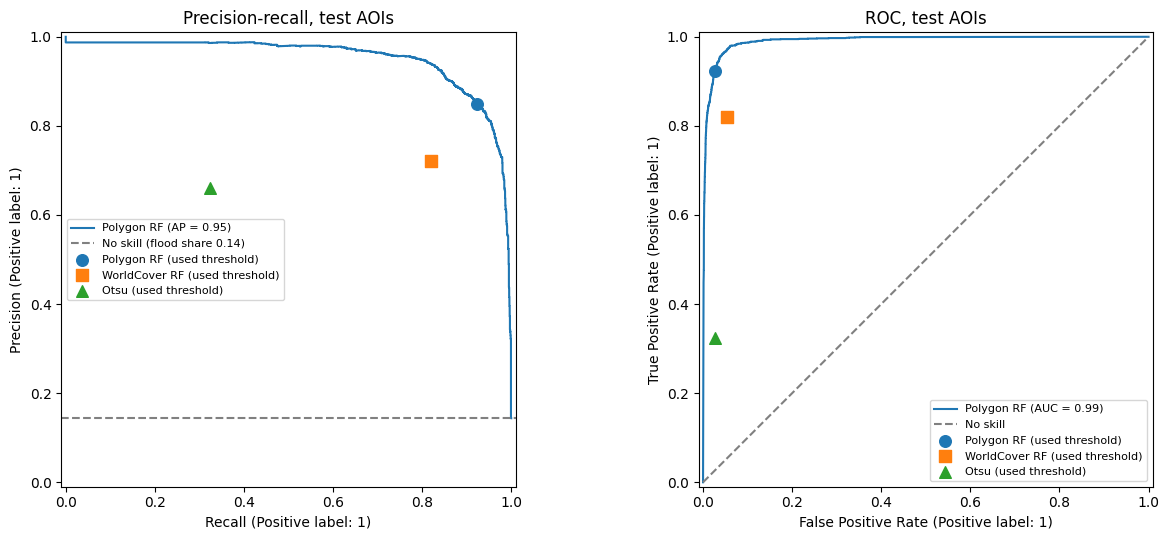

In [12]:
p_rf = rf.predict_proba(test_df[BEST_BANDS])[:, 1]
pooled = test_metrics[test_metrics["aoi"] == "all"].set_index("method")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
PrecisionRecallDisplay.from_predictions(y, p_rf, ax=ax1, name="Polygon RF")
ax1.axhline(y.mean(), ls="--", c="grey", label=f"No skill (flood share {y.mean():.2f})")
RocCurveDisplay.from_predictions(y, p_rf, ax=ax2, name="Polygon RF")
ax2.plot([0, 1], [0, 1], ls="--", c="grey", label="No skill")
for name, mk in [("Polygon RF", "o"), ("WorldCover RF", "s"), ("Otsu", "^")]:
    s = pooled.loc[name]
    ax1.scatter(s["recall"], s["precision"], marker=mk, s=70, zorder=3, label=f"{name} (used threshold)")
    ax2.scatter(s["fpr"], s["recall"], marker=mk, s=70, zorder=3, label=f"{name} (used threshold)")
ax1.set_title("Precision-recall, test AOIs")
ax2.set_title("ROC, test AOIs")
ax1.legend(fontsize=8)
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "pr_roc_test.png", dpi=300)
plt.show()

### Effect of the edge band on the test score

Section 5 drops pixels within `EDGE_BUFFER_M` of a polygon edge from training only. Here the test AOIs are sampled again **with** the `EDGE_BUFFER_M` band (everything else unchanged) and every method is scored again. The gap between `edge_band_m = 0` (the real test) and `EDGE_BUFFER_M` is how much a band would have flattered the score.

In [13]:
# Same test AOIs and study area, but WITH the edge band (diagnostic only; test_df is the no-band test).
test_edge = pd.concat([to_df(sample_aoi(a, edge_m=EDGE_BUFFER_M)) for a in SPLIT["test"]], ignore_index=True)

edge_rows = []
for edge_m, d in [(EDGE_BUFFER_M, test_edge), (0, test_df)]:
    yy = d["label"].values.astype(int)
    ap = average_precision_score(yy, rf.predict_proba(d[BEST_BANDS])[:, 1])
    for name, p in predict_methods(d).items():
        edge_rows.append({"method": name, "edge_band_m": edge_m, **scores(yy, p),
                          "AP": ap if name == "Polygon RF" else np.nan})
edge_effect = pd.DataFrame(edge_rows).set_index(["method", "edge_band_m"])
edge_effect.to_csv(OUT_DIR / "test_metrics_edge_band.csv")
edge_effect[["precision", "recall", "f1", "iou", "AP", "pixels", "flood_share"]].round(3)

,,precision,recall,f1,iou,AP,pixels,flood_share
method,edge_band_m,,,,,,,
Polygon RF,20,0.960,0.995,0.977,0.955,0.999,10827,0.106
WorldCover RF,20,0.796,0.882,0.837,0.719,NaN,10827,0.106
Otsu,20,0.676,0.332,0.445,0.286,NaN,10827,0.106
Polygon RF,0,0.849,0.922,0.884,0.792,0.952,12085,0.144
WorldCover RF,0,0.722,0.820,0.768,0.623,NaN,12085,0.144
Otsu,0,0.661,0.325,0.436,0.278,NaN,12085,0.144


## 9. Earth Engine model (the "ML model" asset)

The same training rows (uploaded from `train_df`) and best settings, trained with `ee.Classifier.smileRandomForest` in probability mode, so it can map any area. The test-set check below should give an average precision close to the scikit-learn model's (they are different RF implementations).

In [14]:
train_fc = ee.FeatureCollection([ee.Feature(None, r) for r in train_df[BEST_BANDS + ["label"]].round(3).to_dict("records")])
gee_rf = (
    ee.Classifier.smileRandomForest(numberOfTrees=BEST_TREES, minLeafPopulation=BEST_LEAF, seed=SEED)
    .setOutputMode("PROBABILITY")
    .train(features=train_fc, classProperty="label", inputProperties=BEST_BANDS)
)

test_fc = ee.FeatureCollection([samples_fc[a] for a in SPLIT["test"]]).flatten()
gee_test = to_df(test_fc.classify(gee_rf, "p"))
print(f"Test average precision, scikit-learn: {average_precision_score(y, p_rf):.3f} | "
      f"Earth Engine: {average_precision_score(gee_test['label'], gee_test['p']):.3f}")

Test average precision, scikit-learn: 0.952 | Earth Engine: 0.954


## 10. Flood map for Northland (Cyclone Gabrielle, 14 Feb 2023)

The Earth Engine model is applied to the whole region on the same event pass and pre-event window as the reference AOIs, inside the same study area (HAND < `HAND_MAX_M`, not permanent water). The flood raster is downloaded to `OUT_DIR` in NZTM so the remaining steps run locally against the data-pipeline layers.

In [15]:
NORTHLAND = (
    ee.FeatureCollection("FAO/GAUL/2015/level1")
    .filter(ee.Filter.eq("ADM0_NAME", "New Zealand"))
    .filter(ee.Filter.eq("ADM1_NAME", "Northland"))
    .geometry()
)
event_cols = ["event_date_utc", "before_start", "before_end", "relative_orbit"]
assert (aois[event_cols].nunique() == 1).all(), "Northland AOIs disagree on the event pass / pre-event window"
ev = aois.iloc[0]

stack_nl = feature_stack(
    s1_collection(NORTHLAND, ev.before_start, ev.before_end, ev.relative_orbit),
    s1_collection(NORTHLAND, *around(pd.Timestamp(ev.event_date_utc, tz="UTC")), ev.relative_orbit),
).clip(NORTHLAND)
flood_prob = stack_nl.select(BEST_BANDS).classify(gee_rf).rename("flood_prob")
flood = flood_prob.gte(THRESHOLD).And(permanent_water.Not()).And(hand.lt(HAND_MAX_M))   # same study area as training
flood = flood.And(flood.selfMask().connectedPixelCount(100, True).gte(MIN_PATCH_PIXELS).unmask(0)).rename("flood").toByte()

Map = geemap.Map(center=[-35.6, 173.9], zoom=8, basemap="HYBRID")
Map.addLayer(stack_nl.select("post_VV"), {"min": -25, "max": 0}, "VV event", False)
Map.addLayer(flood_prob.updateMask(flood_prob.gt(0.2)), {"min": 0.2, "max": 1, "palette": ["yellow", "red"]}, "Flood probability", False)
Map.addLayer(flood.selfMask(), {"palette": ["cyan"]}, "Flood (Polygon RF)")
display(Map)

flood_path = OUT_DIR / f"{REGION}_flood.tif"
geemap.download_ee_image(flood, filename=str(flood_path), region=NORTHLAND, scale=MAP_SCALE_M, crs="EPSG:2193")
print("Saved:", flood_path)

Map(center=[-35.6, 173.9], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

  0%|          |0/34 tiles [00:00<?]

Saved: /content/drive/MyDrive/GEOG 761 Group Project/Project Data/processed/northland_flood.tif


## 11. Depth: bathtub model on the LINZ LiDAR DEM

Same idea as the earlier Auckland test: water surface = height of the dry ground touching the flood, depth = water surface − ground, inside the flood only. Two changes:

- Ground is the **LINZ LiDAR DEM** from the data pipeline (bare earth, 10 m, averaged to `MAP_SCALE_M`), not GLO-30 (a surface model that includes buildings and trees).
- The water surface is the **mean** boundary height within a `WSE_WINDOW_M` square (a fast box filter), instead of a median in a circle. Deep inside large floods, where no boundary falls within the window, the water level of the nearest pixel that has one is used (flat water surface).

In [16]:
import rasterio
from rasterio.warp import reproject, Resampling
from scipy import ndimage

with rasterio.open(flood_path) as src:
    flood_arr = src.read(1) == 1          # nodata and 0 -> not flooded
    grid = {"transform": src.transform, "crs": src.crs, "shape": src.shape}
    profile = src.profile


def to_grid(path, resampling):
    # Read a raster onto the flood grid (float32, NaN = no data).
    out = np.full(grid["shape"], np.nan, dtype="float32")
    with rasterio.open(path) as s:
        reproject(rasterio.band(s, 1), out, dst_transform=grid["transform"], dst_crs=grid["crs"],
                  dst_nodata=np.nan, resampling=resampling)
    return out


def bathtub_depth(flood, ground, window_m=WSE_WINDOW_M, px_m=MAP_SCALE_M):
    boundary = ndimage.binary_dilation(flood, structure=np.ones((3, 3))) & ~flood & np.isfinite(ground)
    size = int(window_m / px_m) | 1
    total = ndimage.uniform_filter(np.where(boundary, ground, 0).astype("float32"), size)
    share = ndimage.uniform_filter(boundary.astype("float32"), size)
    wse = np.where(share > 1e-6, total / np.maximum(share, 1e-6), np.nan)
    nearest = ndimage.distance_transform_edt(np.isnan(wse), return_distances=False, return_indices=True)
    wse = wse[tuple(nearest)]   # fill gaps with the nearest computed water level
    return np.where(flood, np.maximum(wse - ground, 0), np.nan).astype("float32")


ground = to_grid(RAW_DIR / f"{REGION}_lidar_dem_10m.tif", Resampling.average)
depth = bathtub_depth(flood_arr, ground)
with rasterio.open(OUT_DIR / f"{REGION}_depth.tif", "w", **{**profile, "dtype": "float32", "nodata": np.nan}) as dst:
    dst.write(depth, 1)

d = depth[np.isfinite(depth)]
depth_stats = {"mean": round(float(d.mean()), 2), "p50": round(float(np.percentile(d, 50)), 2),
               "p95": round(float(np.percentile(d, 95)), 2), "flood_px_without_depth_pct": round(float(100 * (1 - d.size / flood_arr.sum())), 1)}
print(f"Flooded area: {flood_arr.sum() * MAP_SCALE_M**2 / 1e6:.1f} km2 | depth (m): {depth_stats}")

Flooded area: 218.8 km2 | depth (m): {'mean': 1.5, 'p50': 0.95, 'p95': 4.89, 'flood_px_without_depth_pct': 0.0}


## 12. Flood polygons with depth and population

Connected flood pixels become polygons. Each gets its area, mean and max depth, and an estimated population from WorldPop 2020 (people per 100 m cell spread evenly over the 30 m pixels inside it).

In [17]:
from rasterio.features import shapes
from shapely.geometry import shape

pop_path = RAW_DIR / f"{REGION}_population_2020.tif"
with rasterio.open(pop_path) as s:
    lat = (s.bounds.top + s.bounds.bottom) / 2
    cell_m2 = abs(s.res[0] * s.res[1]) * 111_320**2 * np.cos(np.radians(lat))   # WorldPop cells are in degrees
people = np.nan_to_num(to_grid(pop_path, Resampling.average)) * (MAP_SCALE_M**2 / cell_m2)   # people per map pixel

labels, n = ndimage.label(flood_arr, structure=np.ones((3, 3)))
ids = np.arange(1, n + 1)
has_depth = np.isfinite(depth)
stats = pd.DataFrame({
    "flood_id": ids,
    "area_ha": ndimage.sum(flood_arr, labels, ids) * MAP_SCALE_M**2 / 1e4,
    "depth_mean_m": ndimage.sum(np.where(has_depth, depth, 0), labels, ids) / np.maximum(ndimage.sum(has_depth, labels, ids), 1),
    "depth_max_m": ndimage.maximum(np.where(has_depth, depth, 0), labels, ids),
    "people": ndimage.sum(people, labels, ids),
})

polys = [(shape(g), int(v)) for g, v in shapes(labels, mask=labels > 0, transform=grid["transform"], connectivity=8)]
flood_gdf = (
    gpd.GeoDataFrame({"flood_id": [v for _, v in polys]}, geometry=[g for g, _ in polys], crs=grid["crs"])
    .dissolve("flood_id").reset_index().merge(stats, on="flood_id")
)
print(f"Flood polygons: {len(flood_gdf)} | exposed population (approx.): {flood_gdf['people'].sum():,.0f}")

Flood polygons: 1422 | exposed population (approx.): 1,067


## 13. Infrastructure exposure (LINZ)

From `flood_data_pipeline.ipynb`:

- **Critical infrastructure:** NZ Building Outlines. The `use` field names hospitals, schools and other critical buildings; most buildings are `Unknown`, so all buildings are counted as well.
- **Transport infrastructure:** NZ Road Centrelines (Topo 1:50k), measured in km.

Counts are attached to each flood polygon for the pop-ups and summed for Northland.

In [18]:
buildings = gpd.read_file(RAW_DIR / f"{REGION}_building_outlines.geojson").to_crs(2193)
buildings["use"] = buildings["use"].fillna("Unknown")
roads = gpd.read_file(RAW_DIR / f"{REGION}_road_centrelines.geojson").to_crs(2193)
roads = roads[roads.geom_type.isin(["LineString", "MultiLineString"])]
areas = flood_gdf[["geometry"]]

hit = gpd.sjoin(buildings[["use", "geometry"]], areas, predicate="intersects")
flood_gdf["buildings"] = hit.groupby("index_right").size().reindex(flood_gdf.index, fill_value=0)
named = hit[hit["use"] != "Unknown"]
flood_gdf["building_uses"] = named.groupby("index_right")["use"].agg(lambda u: ", ".join(sorted(set(u)))).reindex(flood_gdf.index, fill_value="")

cut = gpd.overlay(roads[["geometry"]], areas.reset_index(), how="intersection", keep_geom_type=True)
road_km = cut.length.groupby(cut["index"]).sum() / 1000
flood_gdf["roads_km"] = road_km.reindex(flood_gdf.index, fill_value=0).round(2)

exposure = pd.DataFrame([
    {"layer": "buildings (all)", "total": len(buildings), "affected": hit.index.nunique(), "unit": "buildings"},
    {"layer": "roads", "total": round(roads.length.sum() / 1000, 1), "affected": round(road_km.sum(), 1), "unit": "km"},
], dtype=object)   # keep building counts as integers
affected_uses = buildings.loc[hit.index.unique(), "use"].value_counts().rename("affected buildings")
exposure.to_csv(OUT_DIR / "infrastructure_exposure.csv", index=False)
affected_uses.to_csv(OUT_DIR / "affected_buildings_by_use.csv")
display(exposure)
affected_uses

,layer,total,affected,unit
0,buildings (all),160923,313,buildings
1,roads,10312.4,86.3,km


,affected buildings
use,
Unknown,311
School,2


## 14. Map with pop-up metadata

Flood polygons coloured by mean depth; click one for its area, depth, population, buildings and roads. Saved as `northland_flood_map.html` in `OUT_DIR`, which opens in any browser. Polygons are simplified by 15 m to keep the file small; `northland_flood_polygons.geojson` keeps the full geometry.

In [19]:
import folium
import branca.colormap as cm

out = flood_gdf.drop(columns="flood_id").to_crs(4326)
num_cols = ["area_ha", "depth_mean_m", "depth_max_m", "people", "buildings", "roads_km"]
out[num_cols] = out[num_cols].astype(float).round(2)
out.to_file(OUT_DIR / f"{REGION}_flood_polygons.geojson", driver="GeoJSON")
web = out.assign(geometry=flood_gdf.geometry.simplify(15).to_crs(4326))

depth_cmap = cm.LinearColormap(["#deebf7", "#6baed6", "#08306b"], vmin=0, vmax=3, caption="Mean flood depth (m)")


def style(feature):
    d = feature["properties"]["depth_mean_m"]
    return {"fillColor": depth_cmap(min(d or 0, 3)), "color": "#08306b", "weight": 0.5, "fillOpacity": 0.75}


m = folium.Map(location=[-35.6, 173.9], zoom_start=9, tiles=None)
folium.TileLayer("https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}", attr="Google", name="Hybrid").add_to(m)

prob_map = flood_prob.updateMask(flood_prob.gt(0.2)).getMapId(
    {"min": 0.2, "max": 1, "palette": ["yellow", "red"]})
folium.TileLayer(
    tiles=prob_map["tile_fetcher"].url_format, attr="Google Earth Engine",
    name="Flood probability", overlay=True, show=False,
).add_to(m)

folium.GeoJson(
    web, name="Flood polygons", style_function=style,
    popup=folium.GeoJsonPopup(fields=num_cols + ["building_uses"],
                              aliases=["Area (ha)", "Mean depth (m)", "Max depth (m)", "People (approx.)",
                                       "Buildings", "Road (km)", "Named building uses"]),
    tooltip=folium.GeoJsonTooltip(fields=["depth_mean_m", "people"], aliases=["Mean depth (m)", "People"]),
).add_to(m)
depth_cmap.add_to(m)
folium.LayerControl().add_to(m)
m.save(str(OUT_DIR / f"{REGION}_flood_map.html"))
m

## 15. Summary numbers

In [20]:
summary = {
    "event": "Cyclone Gabrielle, Northland",
    "event_pass_utc": ev.event_date_utc,
    "split": SPLIT,
    "best_model": {"bands": best["bands"], "trees": BEST_TREES, "min_leaf": BEST_LEAF,
                   "probability_threshold": round(THRESHOLD, 3), "valid_AP": round(float(best["valid_AP"]), 3)},
    "test_metrics_all_aois": pooled[["precision", "recall", "f1", "iou", "accuracy"]].round(3).to_dict("index"),
    "test_metrics_no_edge_band": {m: r.dropna().round(3).to_dict() for m, r in
                                  edge_effect.xs(0, level="edge_band_m")[["precision", "recall", "f1", "iou", "AP"]].iterrows()},
    "northland": {
        "flood_area_km2": round(float(flood_arr.sum()) * MAP_SCALE_M**2 / 1e6, 1),
        "flood_polygons": len(flood_gdf),
        "exposed_population_approx": round(float(flood_gdf["people"].sum())),
        "depth_stats_m": depth_stats,
        "infrastructure": exposure.to_dict("records"),
        "affected_buildings_by_use": affected_uses.to_dict(),
    },
}
with open(OUT_DIR / "results_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

{
  "event": "Cyclone Gabrielle, Northland",
  "event_pass_utc": "2023-02-14 07:08:00",
  "split": {
    "train": [
      "01",
      "02",
      "05",
      "06"
    ],
    "valid": [
      "07"
    ],
    "test": [
      "03",
      "04"
    ]
  },
  "best_model": {
    "bands": "event + change + terrain",
    "trees": 200,
    "min_leaf": 5,
    "probability_threshold": 0.425,
    "valid_AP": 0.978
  },
  "test_metrics_all_aois": {
    "Polygon RF": {
      "precision": 0.849,
      "recall": 0.922,
      "f1": 0.884,
      "iou": 0.792,
      "accuracy": 0.965
    },
    "WorldCover RF": {
      "precision": 0.722,
      "recall": 0.82,
      "f1": 0.768,
      "iou": 0.623,
      "accuracy": 0.929
    },
    "Otsu": {
      "precision": 0.661,
      "recall": 0.325,
      "f1": 0.436,
      "iou": 0.278,
      "accuracy": 0.879
    }
  },
  "test_metrics_no_edge_band": {
    "Polygon RF": {
      "precision": 0.849,
      "recall": 0.922,
      "f1": 0.884,
      "iou": 0.792,
   

## 16. Data sources

| Data | Source | Resolution | Use |
|---|---|---|---|
| Reference flood polygons, Cyclone Gabrielle | Team-digitised (`data/test`, not in repo) | 20 m grid | Training labels and test reference |
| Sentinel-1 GRD (IW, VV+VH) | ESA Copernicus via Google Earth Engine | 10 m (analysed at 20-30 m) | Flood detection, before and during the event |
| Land cover | ESA WorldCover v200 (2021) | 10 m | Permanent water; WorldCover baseline labels |
| Surface water occurrence | JRC Global Surface Water v1.4 | 30 m | Permanent water |
| Elevation | Copernicus GLO-30 DEM (2024 release) | 30 m | Elevation and slope bands in the model; terrain rule for the baselines |
| Elevation (depth) | LINZ NZ LiDAR 1 m DEM (via `flood_data_pipeline.ipynb`) | 10 m | Bathtub depth |
| Height above nearest drainage | MERIT Hydro v1.0.1 | 90 m | Study area; candidate feature |
| Population | WorldPop 100 m (2020) | 100 m | Exposed population |
| Critical infrastructure | LINZ NZ Building Outlines (layer 101290) | Vector | Buildings in flood, by use |
| Transport infrastructure | LINZ NZ Road Centrelines, Topo 1:50k (layer 50329) | Vector | Road km in flood |

## 17. Known limitations

- The reference polygons were made from the same Sentinel-1 scene (`event_scene` = S1A 2023-02-14 07:08 UTC, orbit 81) as the model's event image. In an earlier run, the Polygon RF's test F1 was 0.998 with a 40 m edge band on the test pixels and 0.855 (AP 0.937) without it; that band removed about 60% of the test flood pixels. Test is now always scored without a band (section 8), so quote the new no-band numbers after re-running. Even then the score is agreement with the reference method (circular), not independent accuracy. To get an independent number, hand-check a test AOI against aerial or Sentinel-2 imagery (e.g. LINZ post-Gabrielle aerials).
- Only 2 pre-event Sentinel-1 scenes per AOI fall in the 1 Jan-12 Feb window on orbit 81, so the pre-event "median" is effectively a mean of two dates and does not suppress a wet date (e.g. Cyclone Hale).
- "Dry" = inside the AOI box but not in a reference polygon. Floods the reference missed become dry labels. Results apply only to the study area (HAND < `HAND_MAX_M`), and the Northland map ignores ground above that height.
- Only 7 AOIs from one event in one region; validation is a single AOI (07), so the chosen threshold is uncertain. The Northland map also covers the training AOIs; quote accuracy from the test AOIs only.
- Sentinel-1 revisit: the 14 Feb pass may miss the flood peak.
- SAR under-detects flooding in built-up areas and under vegetation (double bounce raises backscatter).
- Bathtub depth is a flat-water approximation (mean boundary height within `WSE_WINDOW_M`), on a DEM averaged to 30 m. WorldPop is a 2020 estimate. LINZ building outlines in Northland come from 2014-2016 aerial photos, so newer buildings are missing.
- The Earth Engine probability layer in `northland_flood_map.html` uses a temporary tile URL that expires after a few hours; the flood polygons in the HTML do not expire.
- Tuning and test metrics come from the scikit-learn RF; maps come from the Earth Engine RF trained on the same samples (section 9 compares them).

## 18. Other days: the same Polygon RF on more Sentinel-1 passes

Reruns sections 10-14 for extra passes, reusing the Earth Engine model and the local layers already in this session (run sections 1-14 first). Only the pass changes: the event image is that pass's scenes, and the pre-event baseline is built from the **same orbit** (up to the pass, never later than `before_end`).

The model was trained on the 14 Feb pass (orbit 81) only. Other orbits and directions have other viewing angles, so those maps are **unvalidated**, and there is no reference polygon for them.

In [21]:
# Step 1: list the passes over Northland. Copy the ones you want into PASSES below.
D0, D1 = "2023-02-10", "2023-02-21"   # end exclusive
meta = s1_collection(NORTHLAND, D0, D1).map(lambda i: ee.Feature(None, {
    "t": i.date().millis(), "orbit": i.get("relativeOrbitNumber_start"), "direction": i.get("orbitProperties_pass")}))
sc = to_df(ee.FeatureCollection(meta))
sc["time"] = pd.to_datetime(sc["t"], unit="ms", utc=True)
sc["orbit"] = sc["orbit"].astype(int)
sc["date"] = sc["time"].dt.strftime("%Y-%m-%d")
(sc.groupby(["date", "orbit", "direction"]).agg(scenes=("t", "size"), first_utc=("time", "min"), last_utc=("time", "max"))
   .reset_index())

,date,orbit,direction,scenes,first_utc,last_utc
0,2023-02-11,44,DESCENDING,1,2023-02-11 17:45:42+00:00,2023-02-11 17:45:42+00:00
1,2023-02-14,81,ASCENDING,2,2023-02-14 07:08:26+00:00,2023-02-14 07:08:51+00:00
2,2023-02-18,146,DESCENDING,1,2023-02-18 17:37:43+00:00,2023-02-18 17:37:43+00:00
3,2023-02-19,154,ASCENDING,2,2023-02-19 07:16:29+00:00,2023-02-19 07:16:54+00:00


In [23]:
# Step 2: edit PASSES (UTC time of the first scene, relative orbit), then run. Passes with partial coverage give partial maps.
PASSES = [
    {"time": "2023-02-11 17:45", "orbit": 44},   # before the event, descending (1 scene: likely partial coverage)
    {"time": "2023-02-14 07:08", "orbit": 81},   # the event pass (reuses northland_flood.tif)
    {"time": "2023-02-18 17:37", "orbit": 146},  # after, descending (1 scene: likely partial coverage)
    {"time": "2023-02-19 07:16", "orbit": 154},  # after, ascending
]

from shapely.geometry import mapping

MULTI_DIR = OUT_DIR / "multiday"
MULTI_DIR.mkdir(exist_ok=True)
EVENT_T = pd.Timestamp(ev.event_date_utc, tz="UTC")


def flood_for_pass(t, orbit):
    pre_end = min(pd.Timestamp(ev.before_end, tz="UTC"), t - pd.Timedelta(hours=1))   # never include the pass itself
    pre = s1_collection(NORTHLAND, ev.before_start, int(pre_end.timestamp() * 1000), orbit)
    post = s1_collection(NORTHLAND, *around(t), orbit)
    stack = feature_stack(pre, post).clip(NORTHLAND)
    flood = stack.select(BEST_BANDS).classify(gee_rf).gte(THRESHOLD).And(permanent_water.Not()).And(hand.lt(HAND_MAX_M))
    return flood.And(flood.selfMask().connectedPixelCount(100, True).gte(MIN_PATCH_PIXELS).unmask(0)).rename("flood").toByte()


def rc(c):
    return [rc(x) for x in c] if isinstance(c[0], (list, tuple)) else [round(c[0], 5), round(c[1], 5)]


def polygons_for(arr):
    # sections 11-13 on one flood array: depth, polygons, people, buildings, roads
    depth = bathtub_depth(arr, ground)
    labels, n = ndimage.label(arr, structure=np.ones((3, 3)))
    ids = np.arange(1, n + 1)
    has = np.isfinite(depth)
    st = pd.DataFrame({
        "flood_id": ids,
        "area_ha": ndimage.sum(arr, labels, ids) * MAP_SCALE_M**2 / 1e4,
        "depth_mean_m": ndimage.sum(np.where(has, depth, 0), labels, ids) / np.maximum(ndimage.sum(has, labels, ids), 1),
        "depth_max_m": ndimage.maximum(np.where(has, depth, 0), labels, ids),
        "people": ndimage.sum(people, labels, ids),
    })
    pl = [(shape(g), int(v)) for g, v in shapes(labels, mask=labels > 0, transform=grid["transform"], connectivity=8)]
    g = (gpd.GeoDataFrame({"flood_id": [v for _, v in pl]}, geometry=[x for x, _ in pl], crs=grid["crs"])
         .dissolve("flood_id").reset_index().merge(st, on="flood_id"))
    areas = g[["geometry"]]
    hit = gpd.sjoin(buildings[["use", "geometry"]], areas, predicate="intersects")
    g["buildings"] = hit.groupby("index_right").size().reindex(g.index, fill_value=0)
    named = hit[hit["use"] != "Unknown"]
    g["building_uses"] = named.groupby("index_right")["use"].agg(lambda u: ", ".join(sorted(set(u)))).reindex(g.index, fill_value="")
    cut = gpd.overlay(roads[["geometry"]], areas.reset_index(), how="intersection", keep_geom_type=True)
    g["roads_km"] = (cut.length.groupby(cut["index"]).sum() / 1000).reindex(g.index, fill_value=0).round(2)
    return g, depth


results = []
for p in PASSES:
    t, orbit = pd.Timestamp(p["time"], tz="UTC"), int(p["orbit"])
    tag = f"{t:%Y-%m-%d}_o{orbit}"
    is_event = t.floor("min") == EVENT_T.floor("min") and orbit == int(ev.relative_orbit)
    tif = flood_path if is_event else OUT_DIR / f"{REGION}_flood_{tag}.tif"
    if not tif.exists():
        geemap.download_ee_image(flood_for_pass(t, orbit), filename=str(tif), region=NORTHLAND, scale=MAP_SCALE_M, crs="EPSG:2193")
    with rasterio.open(tif) as src:
        assert src.shape == grid["shape"], f"{tag}: raster grid differs from the event flood raster"
        arr = src.read(1) == 1
    if not arr.any():
        print(tag, "no flood pixels")
        continue
    g, depth = polygons_for(arr)
    web = g.assign(geometry=g.geometry.simplify(15)).to_crs(4326)
    rows = []
    for r in web.itertuples():
        if r.geometry.is_empty:
            continue
        m = mapping(r.geometry)
        rows.append({"id": len(rows) + 1, "a": round(r.area_ha, 2), "dm": round(r.depth_mean_m, 2), "dx": round(r.depth_max_m, 2),
                     "p": round(r.people, 1), "b": int(r.buildings), "r": float(r.roads_km), "u": r.building_uses,
                     "g": m["type"], "c": rc(m["coordinates"])})
    (MULTI_DIR / f"{tag}.json").write_text(json.dumps(rows, separators=(",", ":")))   # same compact format as the dashboard data
    d = depth[np.isfinite(depth)]
    results.append({"pass": tag, "event_pass": is_event, "flood_km2": round(arr.sum() * MAP_SCALE_M**2 / 1e6, 1), "polygons": len(g),
                    "people": round(float(g["people"].sum())), "buildings": int(g["buildings"].sum()),
                    "roads_km": round(float(g["roads_km"].sum()), 1), "depth_mean_m": round(float(d.mean()), 2),
                    "depth_p95_m": round(float(np.percentile(d, 95)), 2)})
    print(results[-1])

multiday = pd.DataFrame(results)
multiday.to_csv(MULTI_DIR / "multiday_summary.csv", index=False)
multiday

  0%|          |0/34 tiles [00:00<?]

{'pass': '2023-02-11_o44', 'event_pass': False, 'flood_km2': np.float64(1.4), 'polygons': 111, 'people': 10, 'buildings': 1, 'roads_km': 0.5, 'depth_mean_m': 0.53, 'depth_p95_m': 3.03}
{'pass': '2023-02-14_o81', 'event_pass': True, 'flood_km2': np.float64(218.8), 'polygons': 1422, 'people': 1067, 'buildings': 313, 'roads_km': 86.2, 'depth_mean_m': 1.5, 'depth_p95_m': 4.89}


  0%|          |0/34 tiles [00:00<?]

{'pass': '2023-02-18_o146', 'event_pass': False, 'flood_km2': np.float64(44.3), 'polygons': 310, 'people': 193, 'buildings': 31, 'roads_km': 6.7, 'depth_mean_m': 0.96, 'depth_p95_m': 2.8}


  0%|          |0/34 tiles [00:00<?]

{'pass': '2023-02-19_o154', 'event_pass': False, 'flood_km2': np.float64(10.3), 'polygons': 295, 'people': 28, 'buildings': 7, 'roads_km': 0.3, 'depth_mean_m': 0.88, 'depth_p95_m': 2.75}


,pass,event_pass,flood_km2,polygons,people,buildings,roads_km,depth_mean_m,depth_p95_m
0,2023-02-11_o44,False,1.4,111,10,1,0.5,0.53,3.03
1,2023-02-14_o81,True,218.8,1422,1067,313,86.2,1.50,4.89
2,2023-02-18_o146,False,44.3,310,193,31,6.7,0.96,2.80
3,2023-02-19_o154,False,10.3,295,28,7,0.3,0.88,2.75
